# Feature engineering and classical baseline (Baseline A)
Runs everything for Sections 5 and 6A. Every number in the report comes from
a cell below, and every result is saved to `results/classical/`.

Order: setup -> Subtask 1 grid -> LOWO selection -> diagnostics -> ablations
-> Subtask 2 -> save tables and figure.

## Cell 1: setup (Colab)
Set `REPO` to the folder where the team repo is cloned in your Drive.
On a local machine, just run the notebook from the repo root.

In [1]:
import os, sys, json
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    REPO = '/content/drive/MyDrive/SenseShift-Semantic-change-across-multiple-time-periods-main'
    os.chdir(REPO)
    !pip -q install bcubed
REPO = os.getcwd() if not IN_COLAB else REPO
if os.path.basename(REPO) == 'notebooks':
    os.chdir('..'); REPO = os.getcwd()
sys.path.insert(0, REPO)

import numpy as np, pandas as pd
from data_loader import load_language, check_integrity
from src.features import FeatureConfig, definition_features, contexts
from src import classical_baseline as cb

DATA_DIR, LANG = 'data', 'SV'
GOLD1, GOLD2 = f'{DATA_DIR}/{LANG}/subtask1.jsonl', f'{DATA_DIR}/{LANG}/subtask2.jsonl'
OUT = 'results/classical'
os.makedirs(OUT, exist_ok=True)
np.random.seed(cb.SEED)

df = load_language(DATA_DIR, LANG)
_ = check_integrity(df, verbose=False)
print(df.shape, df['word'].nunique(), 'words')
import sklearn, scipy, nltk
print('versions: sklearn', sklearn.__version__, '| scipy', scipy.__version__, '| nltk', nltk.__version__,
      '| pandas', pd.__version__, '| numpy', np.__version__)

Mounted at /content/drive
(1983, 20) 10 words
versions: sklearn 1.6.1 | scipy 1.16.3 | nltk 3.9.1 | pandas 2.2.3 | numpy 2.1.3


## Cell 2: what the features look like
One usage before and after the F4 spelling normalisation and the +-10 word
window (target removed).

In [2]:
r = df[(df.word == 'kvinna') & (df.period_index == 0)].iloc[2]
print('TEXT   :', r.text)
print('TARGET :', r.target_fixed)
print('CONTEXT:', contexts(df.loc[[r.name]], window=10)[0])

TEXT   : 1881 omgifta funnos 6 män , som gifte sig för fjerde gången , och 1 för femte gången , men bland kvinnorna fans ingen sorn gifte sig mer än för tredje gången .
TARGET : kvinnorna
CONTEXT: sig för fjerde gången och för femte gången men bland fans ingen sorn gifte sig mer än för tredje gången


## Cell 3: reference points (trivial baselines, from Section 7)

In [3]:
one = {w: np.zeros((df.word == w).sum(), dtype=int) for w in sorted(df.word.unique())}
single = cb.score_labels(df, one, GOLD1)
SINGLE_F1 = single['per_word_f1']
print('one cluster per word: B3 F1 = %.3f' % single['macro']['fcubed'])

one cluster per word: B3 F1 = 0.756


## Cell 4: Subtask 1 grid
3 feature kinds x 4 windows x 7 thresholds x 5 minimum sizes = 420 settings.
Clustering uses no labels. Each setting is scored once on all words; LOWO
then only reads these per-word scores. Takes a few minutes.

In [4]:
feature_cfgs = [FeatureConfig(k, w) for k in cb.KINDS for w in cb.WINDOWS]
scorer = cb.FastScorer(df, GOLD1)          # in-memory official metric code, cached
grid = cb.build_grid(df, feature_cfgs)
grid_scores = cb.score_grid(df, grid, scorer)
print(len(grid), 'settings scored')

# Safety check: the fast scorer must agree exactly with the file-based scorer.
for i in [0, 100, 250]:
    cfg = grid_scores.config.iloc[i]
    ref = cb.score_labels(df, grid[cfg], GOLD1)
    assert abs(ref['macro']['fcubed'] - grid_scores.f1_macro.iloc[i]) < 1e-9
    assert (np.isnan(ref['rho']) and np.isnan(grid_scores.rho_all.iloc[i])) or \
        abs(ref['rho'] - grid_scores.rho_all.iloc[i]) < 1e-9
print('fast scorer == official file scorer: OK')
grid_scores.assign(config=grid_scores.config.map(lambda c: c.name())) \
    .sort_values('f1_macro', ascending=False)[['config', 'f1_macro', 'rho_all']].head(8)

420 settings scored
fast scorer == official file scorer: OK


,config,f1_macro,rho_all
419,both-all|t=0.99|m=30,0.756342,NaN
418,both-all|t=0.99|m=20,0.756342,NaN
399,both-all|t=0.9|m=30,0.756342,NaN
398,both-all|t=0.9|m=20,0.756342,NaN
394,both-all|t=0.85|m=30,0.756342,NaN
393,both-all|t=0.85|m=20,0.756342,NaN
392,both-all|t=0.85|m=15,0.756342,NaN
391,both-all|t=0.85|m=10,0.756342,NaN


## Cell 5: leave-one-word-out selection, three objectives
For each held-out word the setting is chosen on the other nine words only.
The ten held-out labellings form one out-of-fold file, scored once.

In [5]:
systems = {}
for obj in ['1a', 'combined', '1b']:
    sel = cb.lowo_select(df, grid, grid_scores, scorer, objective=obj, single=SINGLE_F1)
    res = cb.score_labels(df, sel['labels'], GOLD1, keep_file=f'{OUT}/SV_subtask1_{obj}.jsonl')
    systems[obj] = {'sel': sel, 'res': res}
    print(f"{obj:9s} B3 P={res['macro']['precision']:.3f} R={res['macro']['recall']:.3f} "
          f"F1={res['macro']['fcubed']:.3f}  rho={res['rho']:.3f}")

# K-means + silhouette (Giulianelli et al. 2020), same features as the most
# frequently chosen 'combined' setting, no tuning needed.
from collections import Counter
main_feat = Counter(c.feat for c in systems['combined']['sel']['chosen'].values()).most_common(1)[0][0]
km = {w: cb.kmeans_silhouette_labels(cb.word_matrix(g, main_feat)) for w, g in df.groupby('word')}
km_res = cb.score_labels(df, km, GOLD1, keep_file=f'{OUT}/SV_subtask1_kmeans.jsonl')
print(f"kmeans    ({main_feat.name()}) F1={km_res['macro']['fcubed']:.3f} rho={km_res['rho']:.3f}")

1a        B3 P=0.648 R=0.890 F1=0.705  rho=-0.136
combined  B3 P=0.647 R=0.903 F1=0.697  rho=0.001
1b        B3 P=0.659 R=0.529 F1=0.474  rho=-0.361
kmeans    (both-pm5) F1=0.264 rho=0.242


## Cell 6: which settings were chosen (stability across folds)

In [6]:
chosen = pd.DataFrame({obj: {w: c.name() for w, c in s['sel']['chosen'].items()}
                       for obj, s in systems.items()})
chosen

,1a,combined,1b
dumpa,char-pm3|t=0.8|m=15,both-pm5|t=0.93|m=30,char-pm10|t=0.93|m=15
exportera,char-pm3|t=0.8|m=15,both-pm5|t=0.93|m=30,char-pm10|t=0.93|m=15
fru,word-all|t=0.85|m=10,both-pm5|t=0.85|m=10,both-pm5|t=0.85|m=10
fröken,char-pm3|t=0.8|m=15,both-pm5|t=0.93|m=30,char-pm10|t=0.93|m=15
förort,char-pm3|t=0.8|m=10,both-pm5|t=0.93|m=30,char-pm10|t=0.93|m=10
herre,char-pm3|t=0.8|m=15,both-pm5|t=0.93|m=30,char-pm10|t=0.93|m=15
kvinna,char-pm3|t=0.8|m=15,both-pm5|t=0.93|m=30,char-pm3|t=0.95|m=10
motiv,char-pm3|t=0.8|m=15,both-pm5|t=0.93|m=30,char-pm10|t=0.93|m=10
skär,char-pm3|t=0.8|m=15,both-pm5|t=0.93|m=30,char-pm5|t=0.9|m=10
suga,char-pm3|t=0.8|m=15,both-pm10|t=0.97|m=10,both-pm10|t=0.97|m=10


## Cell 7: per-word results for Subtask 1a

In [7]:
per_word_1a = pd.DataFrame({
    'one cluster': SINGLE_F1,
    **{f'agglo ({o})': systems[o]['res']['per_word_f1'] for o in systems},
    'kmeans+sil': km_res['per_word_f1'],
}).round(3)
per_word_1a.loc['macro'] = per_word_1a.mean()
per_word_1a

,one cluster,agglo (1a),agglo (combined),agglo (1b),kmeans+sil
dumpa,0.8490,0.8490,0.849,0.6110,0.2780
exportera,0.9460,0.9460,0.946,0.6090,0.2670
fru,0.8960,0.6270,0.303,0.3030,0.2520
fröken,0.8190,0.8190,0.819,0.6190,0.2640
förort,0.8040,0.5640,0.804,0.2540,0.1970
herre,0.8150,0.8150,0.815,0.8150,0.3320
kvinna,0.7870,0.7870,0.787,0.2430,0.2640
motiv,0.7820,0.7820,0.782,0.4190,0.2670
skär,0.5450,0.5450,0.545,0.5450,0.2450
suga,0.3200,0.3200,0.320,0.3200,0.2770


## Cell 8: era diagnostics for Subtask 1b (EDA F2, F6)
Is our 1b signal real change, or just the spelling/era jump at 1915 -> 2006?

In [8]:
era = pd.DataFrame({o: cb.era_diagnostics(s['res']) for o, s in systems.items()})
era['kmeans+sil'] = pd.Series(cb.era_diagnostics(km_res))

# Shuffle control: same cluster sizes per word, random membership (200 draws).
perm = pd.DataFrame({o: cb.permutation_control(scorer, s['sel']['labels']) for o, s in systems.items()})
perm['kmeans+sil'] = pd.Series(cb.permutation_control(scorer, km))
era = pd.concat([era, perm.drop(index='rho')])
era.round(3)

,1a,combined,1b,kmeans+sil
n_pairs,60.000,60.000,60.000,60.000
n_cross_era,4.000,4.000,4.000,4.000
rho_within_era,-0.197,-0.061,-0.451,0.204
rho_pred_vs_cross_era_flag,0.054,0.099,0.119,0.139
mean_pred_jsd_cross,0.106,0.133,0.261,0.413
mean_pred_jsd_within,0.022,0.041,0.170,0.347
shuffled_mean,-0.126,-0.025,-0.464,0.168
shuffled_sd,0.031,0.012,0.048,0.124
p,0.555,0.005,0.020,0.270


## Cell 9: what do our clusters align with? (EDA F8)
Adjusted mutual information of the clusters with gold sense, era and form.
AMI 0 = no relation, 1 = identical grouping.

In [9]:
align = {o: cb.cluster_alignment(df, s['sel']['labels']) for o, s in systems.items()}
align['kmeans+sil'] = cb.cluster_alignment(df, km)
align_mean = pd.DataFrame({o: a[['n_clusters', 'ami_sense', 'ami_era', 'ami_form']].mean()
                           for o, a in align.items()}).T.round(3)
display(align['1b'].round(3)) if 'display' in dir() else print(align['1b'].round(3))
align_mean

           n_clusters  n_gold_senses  ami_sense  ami_form  ami_era
word                                                              
dumpa               2              6      0.020    -0.003      NaN
exportera           3              3      0.040     0.010      NaN
fru                 6              5      0.031     0.034    0.037
fröken              2              4      0.065     0.022    0.100
förort              7              3      0.068     0.070      NaN
herre               1              8      0.000     0.000    0.000
kvinna              9              5      0.028     0.022    0.022
motiv               4              5     -0.001     0.005    0.062
skär                1              6      0.000     0.000      NaN
suga                1             12      0.000     0.000      NaN


,n_clusters,ami_sense,ami_era,ami_form
1a,1.3,0.013,0.022,0.006
combined,1.5,0.003,0.007,0.003
1b,3.6,0.025,0.044,0.016
kmeans+sil,9.0,0.058,0.063,0.054


## Cell 10: feature ablations (which features matter)
Each variant re-runs the full LOWO selection with the 'combined' objective,
so all rows are validated the same way. Spelling and form variants keep
kind and window fixed at the most-chosen setting (`main_feat`).

In [10]:
def lowo_variant(feature_list):
    g = cb.build_grid(df, feature_list)
    gs = cb.score_grid(df, g, scorer)
    sel = cb.lowo_select(df, g, gs, scorer, objective='combined', single=SINGLE_F1)
    r = cb.score_labels(df, sel['labels'], GOLD1)
    d = cb.era_diagnostics(r)
    return {'B3 F1': r['macro']['fcubed'], 'rho': r['rho'], 'rho within-era': d['rho_within_era']}

ablation = {}
for kind in cb.KINDS:
    ablation[f'{kind} n-grams only (all windows)'] = lowo_variant([FeatureConfig(kind, w) for w in cb.WINDOWS])
ablation['whole sentence only'] = lowo_variant([FeatureConfig(k, None) for k in cb.KINDS])
ablation[f'{main_feat.name()} (reference)'] = lowo_variant([main_feat])
ablation['  - spelling normalisation'] = lowo_variant(
    [FeatureConfig(main_feat.kind, main_feat.window, spelling=False)])
ablation['  + target form'] = lowo_variant(
    [FeatureConfig(main_feat.kind, main_feat.window, keep_target=True)])
ablation = pd.DataFrame(ablation).T.round(3)
ablation

,B3 F1,rho,rho within-era
char n-grams only (all windows),0.756,NaN,NaN
word n-grams only (all windows),0.716,-0.101,-0.156
both n-grams only (all windows),0.697,0.001,-0.061
whole sentence only,0.729,-0.027,-0.095
both-pm5 (reference),0.697,0.001,-0.061
- spelling normalisation,0.702,-0.002,-0.065
+ target form,0.756,NaN,NaN


## Cell 11: Subtask 2 features and their signal per word
AUC = how well a single feature ranks target-sense usages above the rest
within a word (0.5 = no signal).

In [11]:
from sklearn.metrics import roc_auc_score
F = definition_features(df)
auc_feat = pd.DataFrame({c: {w: roc_auc_score(g.target_sense, F.loc[g.index, c])
                             for w, g in df.groupby('word')} for c in cb.RAW}).round(3)
auc_feat.loc['mean'] = auc_feat.mean()
auc_feat

,cos_char,cos_word,stem_overlap,stem_jaccard
dumpa,0.585,0.5040,0.4850,0.4850
exportera,0.369,0.4490,0.5350,0.5350
fru,0.574,0.5020,0.5040,0.5040
fröken,0.819,0.5770,0.4850,0.4850
förort,0.518,0.4080,0.4940,0.4940
herre,0.679,0.4380,0.5350,0.5330
kvinna,0.609,0.5770,0.5070,0.5070
motiv,0.534,0.3880,0.5320,0.5330
skär,0.465,0.5560,0.5870,0.5810
suga,0.598,0.5470,0.5080,0.5090


## Cell 12: Subtask 2 logistic regression, leave-one-word-out

In [12]:
ALL1 = cb.all_ones_f1(df)
s2 = {}
for name, cols, tune in [('LR raw, thr 0.5', cb.RAW, False),
                         ('LR raw, tuned thr', cb.RAW, True),
                         ('LR rank, thr 0.5', cb.RANK, False),
                         ('LR rank, tuned thr', cb.RANK, True)]:
    out = cb.subtask2_lowo(df, F, cols, tune_threshold=tune)
    sc = cb.score_subtask2(df, out['pred'], GOLD2, f'{OUT}/SV_subtask2_{name.replace(" ", "_").replace(",", "")}.jsonl')
    s2[name] = {'out': out, 'score': sc}
    print(f"{name:20s} macro F1 = {sc['macro']:.3f}   mean AUC = {np.mean(list(out['auc'].values())):.3f}")
print(f"{'predict all 1':20s} macro F1 = {np.mean(list(ALL1.values())):.3f}")

LR raw, thr 0.5      macro F1 = 0.325   mean AUC = 0.567
LR raw, tuned thr    macro F1 = 0.469   mean AUC = 0.567
LR rank, thr 0.5     macro F1 = 0.367   mean AUC = 0.566
LR rank, tuned thr   macro F1 = 0.472   mean AUC = 0.566
predict all 1        macro F1 = 0.472


## Cell 13: Subtask 2 per word, chosen thresholds, oracle ceiling
The oracle row uses gold labels to pick the best threshold per word on the
out-of-fold LR score. It is NOT a system, only a ceiling for these features.

In [13]:
best2 = 'LR rank, tuned thr'
oracle = cb.oracle_threshold_f1(df, s2[best2]['out']['prob'])
per_word_2 = pd.DataFrame({
    'positive share': df.groupby('word').target_sense.mean(),
    'all 1': ALL1,
    **{n: s2[n]['score']['per_word'] for n in s2},
    'AUC (rank LR)': s2[best2]['out']['auc'],
    'oracle thr (diag.)': oracle,
    'chosen thr': s2[best2]['out']['thresholds'],
}).round(3)
per_word_2.loc['macro'] = per_word_2.mean()
per_word_2

,positive share,all 1,"LR raw, thr 0.5","LR raw, tuned thr","LR rank, thr 0.5","LR rank, tuned thr",AUC (rank LR),oracle thr (diag.),chosen thr
dumpa,0.3100,0.4740,0.4460,0.4740,0.4330,0.4740,0.5760,0.5170,0.400
exportera,0.9460,0.9720,0.6420,0.9510,0.5690,0.9720,0.4070,0.9720,0.050
fru,0.8940,0.9440,0.0930,0.9440,0.6510,0.9440,0.5740,0.9440,0.400
fröken,0.0570,0.1090,0.1400,0.1090,0.1480,0.1090,0.7160,0.2550,0.050
förort,0.4930,0.6610,0.6010,0.6610,0.4600,0.6610,0.5480,0.6700,0.050
herre,0.0710,0.1320,0.1860,0.1320,0.2030,0.1320,0.7210,0.2520,0.400
kvinna,0.2280,0.3710,0.3470,0.3710,0.3110,0.3710,0.5610,0.4220,0.050
motiv,0.1820,0.3080,0.2920,0.3080,0.2740,0.3080,0.5610,0.3400,0.050
skär,0.2760,0.4320,0.2710,0.4320,0.3200,0.4320,0.4450,0.4390,0.050
suga,0.1860,0.3140,0.2350,0.3140,0.3040,0.3140,0.5500,0.3570,0.050


## Cell 14: coefficients (standardised features, mean +- sd over 10 folds)

In [14]:
coef = {n: s2[n]['out']['coefs'].agg(['mean', 'std']).T for n in ['LR raw, tuned thr', 'LR rank, tuned thr']}
pd.concat(coef, axis=0).round(3)

mean    std
LR raw, tuned thr  cos_char           0.155  0.123
                   cos_word          -0.136  0.094
                   stem_overlap      -0.412  0.154
                   stem_jaccard       0.420  0.141
LR rank, tuned thr cos_char_rank      0.165  0.024
                   cos_word_rank     -0.100  0.027
                   stem_overlap_rank  0.171  0.062
                   stem_jaccard_rank -0.124  0.054

## Cell 14b: plain TF-IDF + logistic regression (Subtask 2)
The textbook baseline: context words (one shared vocabulary) -> LR, LOWO.
The top coefficients show what the model actually relies on.
The within-word cross-validation is a DIAGNOSTIC only (test words have no
labels): it asks whether the contexts carry sense information at all.

In [15]:
tf = cb.tfidf_lr_lowo(df)
tf_score = cb.score_subtask2(df, tf['pred'], GOLD2, f'{OUT}/SV_subtask2_tfidf_LR.jsonl')
print(f"TF-IDF LR (LOWO): macro F1 = {tf_score['macro']:.3f}  mean AUC = {np.mean(list(tf['auc'].values())):.3f}"
      f"  vocabulary = {tf['vocab_size']} words")
print(tf['top_coefficients'].round(2).to_string())
within = cb.tfidf_lr_within_word(df)
within.loc['mean'] = within.mean()
print('\nWithin-word 5-fold CV (diagnostic):')
print(within.round(3).to_string())

TF-IDF LR (LOWO): macro F1 = 0.244  mean AUC = 0.466  vocabulary = 1369 words
   positive_word  pos_coef negative_word  neg_coef
0           hans      2.91         damer     -2.12
1            sin      2.42           upp     -1.64
2         länder      2.33         varit     -1.56
3            min      2.08            åt     -1.21
4          vapen      1.65            en     -1.17
5           blod      1.64            ej     -1.13
6        sverige      1.62         dådet     -1.13
7           kina      1.39       damerna     -1.13
8           från      1.26            då     -1.07
9            små      1.25         julie     -1.01
10      miljoner      1.25           ned     -1.00
11         havet      1.24           fru     -0.99
12          mitt      1.18      damernas     -0.93
13         liten      1.17           bil     -0.92
14           mer      1.09            vm     -0.90

Within-word 5-fold CV (diagnostic):
              f1    auc
word                   
dumpa      0.549  0.7

## Cell 14c: shortcut test (instructor's Example A; EDA F2, F3, F4)
Add the era proxies we excluded (sentence length, old-spelling rate, era)
and check whether performance rises. Also: how well does era ALONE
separate target-sense usages inside each word (AUC, no model)?

In [16]:
from src.features import era_proxy_features, ERA_PROXIES
from sklearn.metrics import roc_auc_score
FE = F.join(era_proxy_features(df))
shortcut = {}
for name, cols in [('definition ranks (baseline)', cb.RANK),
                   ('definition ranks + era proxies', cb.RANK + ERA_PROXIES),
                   ('era proxies only', ERA_PROXIES)]:
    o = cb.subtask2_lowo(df, FE, cols, tune_threshold=True)
    sc = cb.score_subtask2(df, o['pred'], GOLD2, f'{OUT}/_tmp_shortcut.jsonl')
    shortcut[name] = {'macro F1 (LOWO)': sc['macro'], 'mean AUC (LOWO)': np.mean(list(o['auc'].values())),
                      'coef is_modern': o['coefs']['is_modern'].mean() if 'is_modern' in cols else np.nan}
os.remove(f'{OUT}/_tmp_shortcut.jsonl')
shortcut = pd.DataFrame(shortcut).T
print(shortcut.round(3).to_string())
era_auc = {w: roc_auc_score(g.target_sense, 1 - FE.loc[g.index, 'is_modern'])
           for w, g in df.groupby('word') if g.period_index.min() < 5 <= g.period_index.max()}
print('\nWithin-word AUC of "historical era" alone (two-era words; 0.5 = no signal):')
print({w: round(v, 3) for w, v in era_auc.items()})

                                macro F1 (LOWO)  mean AUC (LOWO)  coef is_modern
definition ranks (baseline)               0.472            0.566             NaN
definition ranks + era proxies            0.470            0.499           0.237
era proxies only                          0.472            0.419           0.226

Within-word AUC of "historical era" alone (two-era words; 0.5 = no signal):
{'fru': np.float64(0.252), 'fröken': np.float64(0.643), 'herre': np.float64(0.783), 'kvinna': np.float64(0.599), 'motiv': np.float64(0.668)}


## Cell 15: the 1a / 1b trade-off figure (all 420 settings, in-sample)

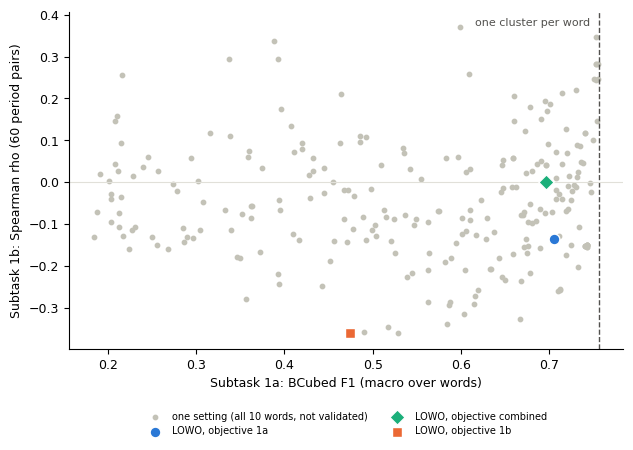

In [17]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(figsize=(6.4, 4.6))
gs = grid_scores.dropna(subset=['rho_all'])
ax.scatter(gs.f1_macro, gs.rho_all, s=10, color='#c3c2b7', label='one setting (all 10 words, not validated)')
marks = {'1a': ('#2a78d6', 'o'), 'combined': ('#1baf7a', 'D'), '1b': ('#eb6834', 's')}
for o, (c, m) in marks.items():
    r = systems[o]['res']
    ax.scatter(r['macro']['fcubed'], r['rho'], s=60, color=c, marker=m, edgecolor='white',
               zorder=3, label=f'LOWO, objective {o}')
ax.axvline(single['macro']['fcubed'], color='#52514e', ls='--', lw=1)
ax.text(single['macro']['fcubed'] - 0.01, ax.get_ylim()[1] * 0.92, 'one cluster per word',
        ha='right', fontsize=8, color='#52514e')
ax.axhline(0, color='#e1e0d9', lw=0.8)
ax.set_xlabel('Subtask 1a: BCubed F1 (macro over words)')
ax.set_ylabel('Subtask 1b: Spearman rho (60 period pairs)')
ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(f'{OUT}/tradeoff_1a_1b.pdf', bbox_inches='tight')
fig.savefig(f'{OUT}/tradeoff_1a_1b.png', dpi=200, bbox_inches='tight')
plt.show()

## Cell 16: save everything for the report

In [18]:
per_word_1a.to_csv(f'{OUT}/subtask1a_per_word.csv')
era.to_csv(f'{OUT}/subtask1b_era_diagnostics.csv')
align_mean.to_csv(f'{OUT}/cluster_alignment_mean.csv')
pd.concat(align, axis=0).to_csv(f'{OUT}/cluster_alignment_per_word.csv')
ablation.to_csv(f'{OUT}/subtask1_ablation.csv')
chosen.to_csv(f'{OUT}/subtask1_chosen_settings.csv')
auc_feat.to_csv(f'{OUT}/subtask2_feature_auc.csv')
per_word_2.to_csv(f'{OUT}/subtask2_per_word.csv')
pd.concat(coef, axis=0).to_csv(f'{OUT}/subtask2_coefficients.csv')
tf['top_coefficients'].to_csv(f'{OUT}/subtask2_tfidf_lr_top_coefficients.csv', index=False)
within.to_csv(f'{OUT}/subtask2_tfidf_lr_within_word_diagnostic.csv')
shortcut.to_csv(f'{OUT}/subtask2_shortcut_test.csv')
# 1b change scores per (word, period pair) and predicted sense shares per period
cb.jsd_table({**{o: s['res'] for o, s in systems.items()}, 'kmeans': km_res}) \
    .to_csv(f'{OUT}/subtask1b_jsd_per_pair.csv', index=False)
pd.concat({o: cb.sense_shares(df, s['sel']['labels']) for o, s in systems.items()} |
          {'kmeans': cb.sense_shares(df, km)}, names=['system', 'row']) \
    .reset_index(level='row', drop=True).reset_index().to_csv(f'{OUT}/subtask1_sense_shares_per_period.csv', index=False)
grid_scores.assign(config=grid_scores.config.map(lambda c: c.name())).to_csv(f'{OUT}/subtask1_grid.csv', index=False)

summary = {
    'one_cluster': {'f1': single['macro']['fcubed']},
    **{f'agglo_{o}': {'precision': s['res']['macro']['precision'], 'recall': s['res']['macro']['recall'],
                      'f1': s['res']['macro']['fcubed'], 'rho': s['res']['rho'],
                      **cb.era_diagnostics(s['res'])} for o, s in systems.items()},
    'kmeans_sil': {'precision': km_res['macro']['precision'], 'recall': km_res['macro']['recall'],
                   'f1': km_res['macro']['fcubed'], 'rho': km_res['rho'], 'features': main_feat.name(),
                   **cb.era_diagnostics(km_res), **perm['kmeans+sil'].drop('rho').to_dict()},
    'in_sample_best_rho_with_f1_floor': float(grid_scores[grid_scores.f1_macro >= single['macro']['fcubed'] - cb.DELTA_1A].rho_all.max()),
    'subtask2': {n: s2[n]['score']['macro'] for n in s2},
    'subtask2_all1': float(np.mean(list(ALL1.values()))),
    'subtask2_tfidf_lr': {'f1': tf_score['macro'], 'auc': float(np.mean(list(tf['auc'].values())))},
    'subtask2_tfidf_lr_within_word_diag': {'f1': float(within.loc['mean', 'f1']), 'auc': float(within.loc['mean', 'auc'])},
    'subtask2_shortcut': shortcut.to_dict(orient='index'),
    'era_alone_within_word_auc': era_auc,
    'seed': cb.SEED,
}
json.dump(summary, open(f'{OUT}/summary.json', 'w'), indent=2, default=float)
print(json.dumps(summary, indent=1, default=float))

{
 "one_cluster": {
  "f1": 0.7563415432223628
 },
 "agglo_1a": {
  "precision": 0.6480242021772655,
  "recall": 0.8898071412663539,
  "f1": 0.7054298989160133,
  "rho": -0.1357582470100402,
  "n_pairs": 60,
  "n_cross_era": 4,
  "rho_within_era": -0.19658267941861057,
  "rho_pred_vs_cross_era_flag": 0.05353224965425315,
  "mean_pred_jsd_cross": 0.10590712747491549,
  "mean_pred_jsd_within": 0.021578175598427497
 },
 "agglo_combined": {
  "precision": 0.6471595443689585,
  "recall": 0.9030723743221134,
  "f1": 0.697015307749275,
  "rho": 0.0012971738666144104,
  "n_pairs": 60,
  "n_cross_era": 4,
  "rho_within_era": -0.060912980828442195,
  "rho_pred_vs_cross_era_flag": 0.09936546600614797,
  "mean_pred_jsd_cross": 0.1328032436421724,
  "mean_pred_jsd_within": 0.04083896276722852
 },
 "agglo_1b": {
  "precision": 0.6585364369466826,
  "recall": 0.5293886758472911,
  "f1": 0.47379574307080585,
  "rho": -0.36102688389253385,
  "n_pairs": 60,
  "n_cross_era": 4,
  "rho_within_era": -0.450